# Task result loader

This notebook opens an existing policy result store, dispatches to the policy-specific formatter, and inspects the returned `PolicyFormattedResults` payload. Use the dropdown below to select a `.zarr` store under `artifacts/`, ordered by newest first.


In [1]:
import json
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

project_root = Path.cwd()
if not (project_root / "tasks").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    import scienceplots  # noqa: F401
except ModuleNotFoundError:
    scienceplots = None
else:
    plt.style.use("science")
from network_creation.observers.social_welfare_observer import NormalizedWelfareObserver
from tasks.policies import load_policy_results
from network_creation.plotting.plot_pair import plot_pair

project_root

PosixPath('/home/hdahmou/Network_creation')

## Load and transform policy results


In [2]:
result_store_candidates = sorted(
    project_root.glob("artifacts/**/*.zarr"),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
if not result_store_candidates:
    raise FileNotFoundError("No .zarr result stores found under artifacts/")

result_store_selector = widgets.Dropdown(
    options=[str(path.relative_to(project_root)) for path in result_store_candidates],
    value=str(result_store_candidates[0].relative_to(project_root)),
    description="Result:",
    layout=widgets.Layout(width="95%"),
)
display(result_store_selector)

Dropdown(description='Result:', layout=Layout(width='95%'), options=('artifacts/notebook_runs/best-response-po…

In [3]:
result_store_path = project_root / result_store_selector.value

formatted = load_policy_results(result_store_path)
input_group = formatted.inputs
output_group = formatted.outputs
status_group = formatted.status
metadata = formatted.metadata
config = json.loads(Path(metadata["config_path"]).read_text(encoding="utf-8"))

{
    "result_store_path": str(metadata["result_store_path"]),
    "config_path": str(metadata["config_path"]),
    "task_name": metadata["task_name"],
    "task_class": metadata["task_class"],
    "output_schema": metadata["output_schema"],
    "input_tensors": {
        name: tensor.shape for name, tensor in input_group["tensors"].items()
    },
    "output_tensors": {
        name: tensor.shape for name, tensor in output_group["tensors"].items()
    },
    "status_tensors": {
        name: tensor.shape for name, tensor in status_group["tensors"].items()
    },
}

{'result_store_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836/best-response-policy-20260417T003836.zarr',
 'config_path': '/home/hdahmou/Network_creation/artifacts/notebook_runs/best-response-policy-20260417T003836/best-response-policy-20260417T003836.dispatch_config.json',
 'task_name': 'best-response-policy',
 'task_class': 'tasks.policies.best_response:BestResponsePolicyRun',
 'output_schema': [{'name': 'central_point_of_dominance.mean',
   'shape': [361],
   'dtype': 'float32'},
  {'name': 'normalized_welfare.mean', 'shape': [361], 'dtype': 'float32'}],
 'input_tensors': {'parameters': (2, 16, 6)},
 'output_tensors': {'timeseries': (2, 16, 2, 361), 'final': (2, 16, 2)},
 'status_tensors': {'success': (2, 16),
  'error': (2, 16),
  'duration_ms': (2, 16)}}

In [4]:
{
    "input_dims": input_group["dims"],
    "output_dims": output_group["dims"],
    "input_label_sizes": {
        name: len(values) for name, values in input_group["labels"].items()
    },
    "output_label_sizes": {
        name: len(values) for name, values in output_group["labels"].items()
    },
}

{'input_dims': {'parameters': ('n_agents', 'parameter_row', 'parameter')},
 'output_dims': {'timeseries': ('n_agents',
   'parameter_row',
   'observable',
   'step'),
  'final': ('n_agents', 'parameter_row', 'observable')},
 'input_label_sizes': {'n_agents': 2, 'parameter_row': 16, 'parameter': 6},
 'output_label_sizes': {'n_agents': 2,
  'parameter_row': 16,
  'observable': 2,
  'step': 361}}

## Plot per-step outputs

This cell plots one figure per `n_agents` slice from `outputs["tensors"]["timeseries"]`.


In [5]:
timeseries = output_group["tensors"]["timeseries"]
success = status_group["tensors"]["success"]
observables = tuple(output_group["labels"]["observable"])
steps = np.asarray(output_group["labels"]["step"])
n_agents_values = np.asarray(output_group["labels"]["n_agents"])
parameter_rows = np.asarray(output_group["labels"]["parameter_row"])


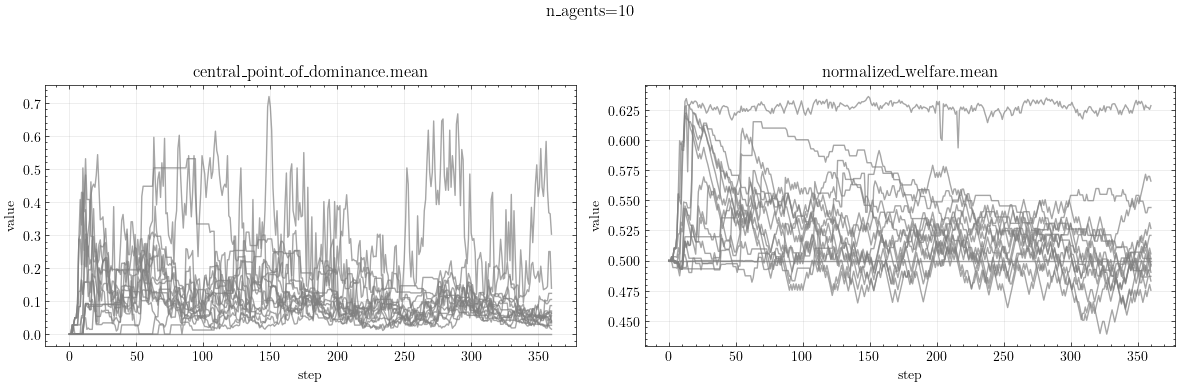

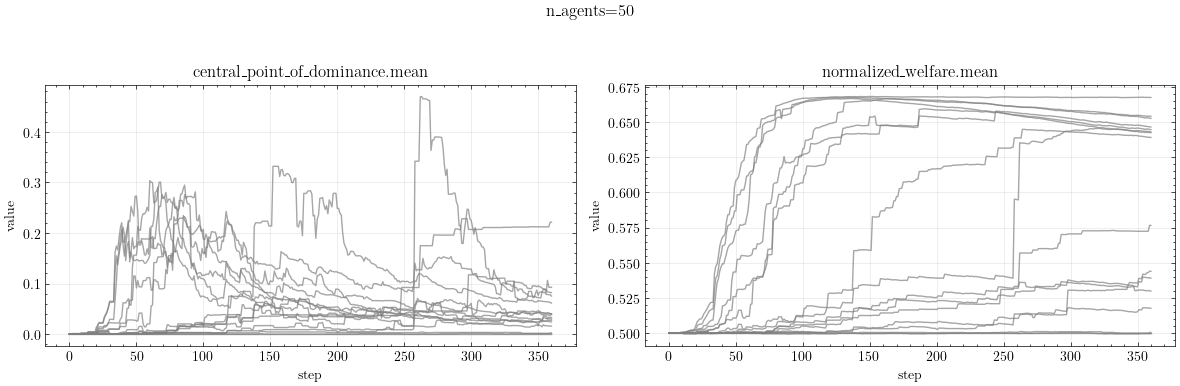

In [6]:
for n_agents_index, n_agents in enumerate(n_agents_values):
    fig, axes = plt.subplots(1, len(observables), figsize=(12, 4), sharex=True)
    axes = np.atleast_1d(axes)
    for observable_index, observable_name in enumerate(observables):
        for parameter_row_index, parameter_row in enumerate(parameter_rows):
            if not success[n_agents_index, parameter_row_index]:
                continue
            axes[observable_index].plot(
                steps,
                timeseries[n_agents_index, parameter_row_index, observable_index],
                alpha=0.7,
                label=f"row={int(parameter_row)}",
                c="gray",
            )
        axes[observable_index].set_title(str(observable_name))
        axes[observable_index].set_xlabel("step")
        axes[observable_index].set_ylabel("value")
        axes[observable_index].grid(alpha=0.3)

    fig.suptitle(f"n_agents={int(n_agents)}")
    handles, labels = axes[0].get_legend_handles_labels()
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


## Final-step pair plots

This cell selects one `n_agents` slice, filters to successful parameter rows, and uses `outputs["tensors"]["final"]` for pair plots.


In [7]:
parameters_grid = input_group["tensors"]["parameters"]
final_grid = output_group["tensors"]["final"]
parameter_labels = tuple(input_group["labels"].get("parameter", ()))
observable_labels = tuple(output_group["labels"]["observable"])
n_agents_values = np.asarray(input_group["labels"]["n_agents"])

In [8]:
target_n_agents_index = 0
selected_n_agents = int(n_agents_values[target_n_agents_index])
success = status_group["tensors"]["success"][target_n_agents_index]

parameters = parameters_grid[target_n_agents_index][success]
final = final_grid[target_n_agents_index][success]

{
    "selected_n_agents": selected_n_agents,
    "selected_parameter_rows": int(success.sum()),
    "parameter_labels": parameter_labels,
}

{'selected_n_agents': 10,
 'selected_parameter_rows': 16,
 'parameter_labels': ('benefit_to_cost_ratio',
  'distance_discount',
  'bridge_value',
  'inertia_term',
  'tau',
  'visibility_distance')}

## Welfare Reference Values

This computes the observer-level `star`, `empty`, and optimized `random` welfare reference values for the selected `n_agents` slice.


In [9]:
benefit_to_cost_ratio = np.unique(
    parameters[:, parameter_labels.index("benefit_to_cost_ratio")]
).item()
distance_discount = np.unique(
    parameters[:, parameter_labels.index("distance_discount")]
).item()

reference_welfare = NormalizedWelfareObserver.reference_values(
    n=selected_n_agents,
    benefit_to_cost_ratio=float(benefit_to_cost_ratio),
    distance_discount=float(distance_discount),
)

reference_welfare

{'star': 0.6487368328445837, 'empty': 0.5, 'random': 0.5623042698785256}

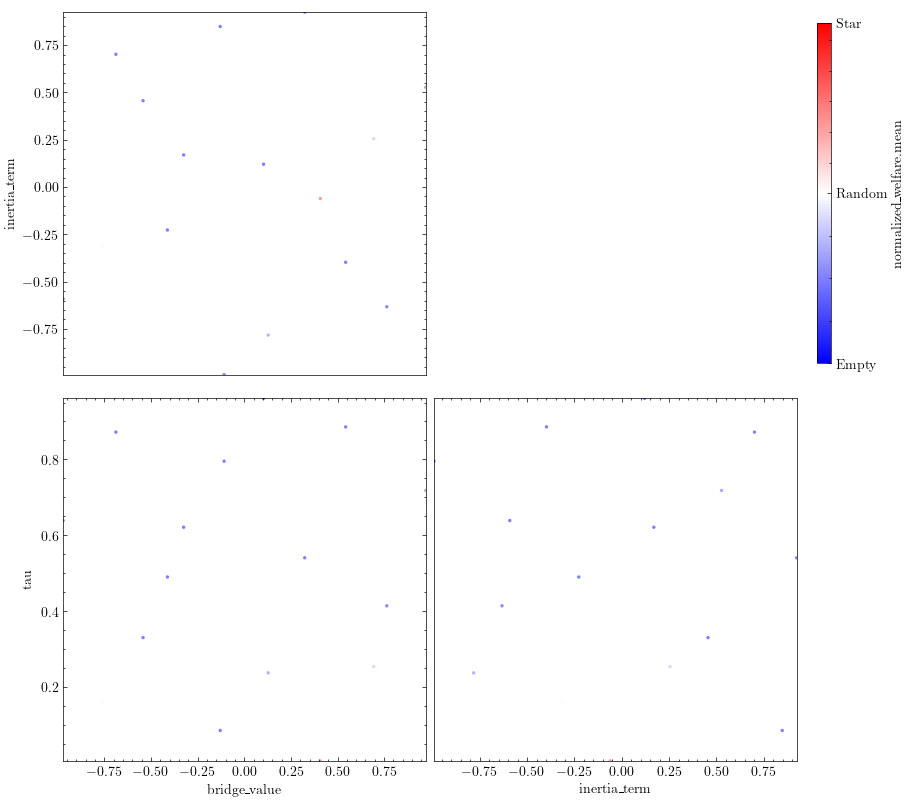

In [10]:
target_idx = 1
target_values = final[:, target_idx]
reference_center = float(reference_welfare["random"])
target_norm = TwoSlopeNorm(
    vmin=reference_welfare["empty"],
    vcenter=reference_center,
    vmax=reference_welfare["star"],
)

fig, axes = plot_pair(
    X=parameters,
    y=target_values,
    labels=parameter_labels,
    label_y=observable_labels[target_idx],
    atol=1e-5,
    base_fig_size=4.0,
    cmap="bwr",
    method="points",
    resolution=50,
    sigma=0.2,
    norm=target_norm,
)

cbar_ax = fig.axes[-1]
cbar_ax.set_yticks(
    [
        reference_welfare["empty"],
        reference_welfare["random"],
        reference_welfare["star"],
    ],
    labels=["Empty", "Random", "Star"],
);

In [11]:
dict(zip(parameter_labels, parameters[final[:, 0].argmax()]))

{'benefit_to_cost_ratio': np.float32(0.5),
 'distance_discount': np.float32(0.9),
 'bridge_value': np.float32(0.40768063),
 'inertia_term': np.float32(-0.061278522),
 'tau': np.float32(0.0052103777),
 'visibility_distance': np.float32(3.0)}

## Status tensors

This cell summarizes failed dense cells from `status["tensors"]` and keeps them aligned with `(n_agents, parameter_row)`.


In [12]:
success = status_group["tensors"]["success"]
error = status_group["tensors"]["error"]
duration_ms = status_group["tensors"]["duration_ms"]
failed_coords = np.argwhere(~success)

{
    "success_shape": tuple(success.shape),
    "failure_count": int((~success).sum()),
    "failed_cells": [
        {
            "n_agents": int(input_group["labels"]["n_agents"][n_agents_index]),
            "parameter_row": int(
                output_group["labels"]["parameter_row"][parameter_row_index]
            ),
            "error": str(error[n_agents_index, parameter_row_index]),
            "duration_ms": float(duration_ms[n_agents_index, parameter_row_index]),
        }
        for n_agents_index, parameter_row_index in failed_coords
    ],
}

{'success_shape': (2, 16), 'failure_count': 0, 'failed_cells': []}